<a href="https://colab.research.google.com/github/Rixdorfer-Kindl/protein-design-pipline-colab/blob/main/%E9%AA%A8%E6%9E%B6%E9%AA%8C%E8%AF%81.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#@title 🛠️ 安装依赖 { display-mode: "form" }
#@markdown 只需要 Biopython，其余（pandas、numpy、scipy、matplotlib）Colab 已自带。

!pip install -q biopython

import Bio, scipy, pandas, numpy, matplotlib
print("✅ 环境就绪 | Biopython", Bio.__version__, "| scipy", scipy.__version__)

✅ 环境就绪 | Biopython 1.88 | scipy 1.16.3


Mounted at /content/drive

group1: 6 个骨架, hotspot(1IVO) = [364, 367]

group2: 8 个骨架, hotspot(1IVO) = [431, 400, 376]

group3: 5 个骨架, hotspot(1IVO) = [392, 397]


,group,file,target_range,ref_covered,min_dist,n_atom_contacts,n_binder_int_res,n_target_int_res,hs364,hs367,hs_min_dist,hs_touched,hs_total,hs431,hs400,hs376,hs392,hs397
0,group1,1_0.pdb,65-235,310-480,4.98,1,1,1,8.59 (→119),11.78 (→122),8.59,0,2,NaN,NaN,NaN,NaN,NaN
1,group1,1_1.pdb,56-226,310-480,5.14,0,0,0,8.77 (→110),8.7 (→113),8.70,0,2,NaN,NaN,NaN,NaN,NaN
2,group1,1_2.pdb,99-269,310-480,5.65,0,0,0,6.85 (→153),9.6 (→156),6.85,0,2,NaN,NaN,NaN,NaN,NaN
3,group1,1_3.pdb,88-258,310-480,5.32,0,0,0,8.58 (→142),6.33 (→145),6.33,0,2,NaN,NaN,NaN,NaN,NaN
4,group1,1_4.pdb,65-235,310-480,5.01,0,0,0,7.64 (→119),9.12 (→122),7.64,0,2,NaN,NaN,NaN,NaN,NaN
5,group1,1_5.pdb,95-265,310-480,5.92,0,0,0,10.67 (→149),9.02 (→152),9.02,0,2,NaN,NaN,NaN,NaN,NaN
6,group2,2_0.pdb,78-248,310-480,4.78,2,1,1,NaN,NaN,7.64,0,3,8.19 (→199),7.64 (→168),8.42 (→144),NaN,NaN
7,group2,2_1.pdb,61-231,310-480,6.19,0,0,0,NaN,NaN,10.14,0,3,10.14 (→182),11.99 (→151),12.37 (→127),NaN,NaN
8,group2,2_2.pdb,57-227,310-480,4.95,1,1,1,NaN,NaN,6.71,0,3,6.71 (→178),7.49 (→147),8.88 (→123),NaN,NaN
9,group2,2_3.pdb,61-231,310-480,7.84,0,0,0,NaN,NaN,8.48,0,3,9.8 (→182),8.48 (→151),11.33 (→127),NaN,NaN


,n,min_dist_median,contacts_median,contacts_max,frac_touching,hs_min_dist_median
group,,,,,,
group1,6,5.23,0.0,1,0.0,8.115
group2,8,5.11,0.5,8,0.0,8.605
group3,5,4.81,3.0,3,0.0,7.850


/tmp/ipykernel_3372/277279090.py:136: UserWarning: Glyph 26368 (\N{CJK UNIFIED IDEOGRAPH-6700}) missing from font(s) DejaVu Sans.
  plt.suptitle(""); plt.tight_layout(); plt.show()
/tmp/ipykernel_3372/277279090.py:136: UserWarning: Glyph 36817 (\N{CJK UNIFIED IDEOGRAPH-8FD1}) missing from font(s) DejaVu Sans.
  plt.suptitle(""); plt.tight_layout(); plt.show()
/tmp/ipykernel_3372/277279090.py:136: UserWarning: Glyph 36317 (\N{CJK UNIFIED IDEOGRAPH-8DDD}) missing from font(s) DejaVu Sans.
  plt.suptitle(""); plt.tight_layout(); plt.show()
/tmp/ipykernel_3372/277279090.py:136: UserWarning: Glyph 31163 (\N{CJK UNIFIED IDEOGRAPH-79BB}) missing from font(s) DejaVu Sans.
  plt.suptitle(""); plt.tight_layout(); plt.show()
/tmp/ipykernel_3372/277279090.py:136: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.suptitle(""); plt.tight_layout(); plt.show()
/tmp/ipykernel_3372/277279090.py:136: UserWarning: Glyph 23376 (\N{CJK UNIFIED IDEOGRAPH-5B50})

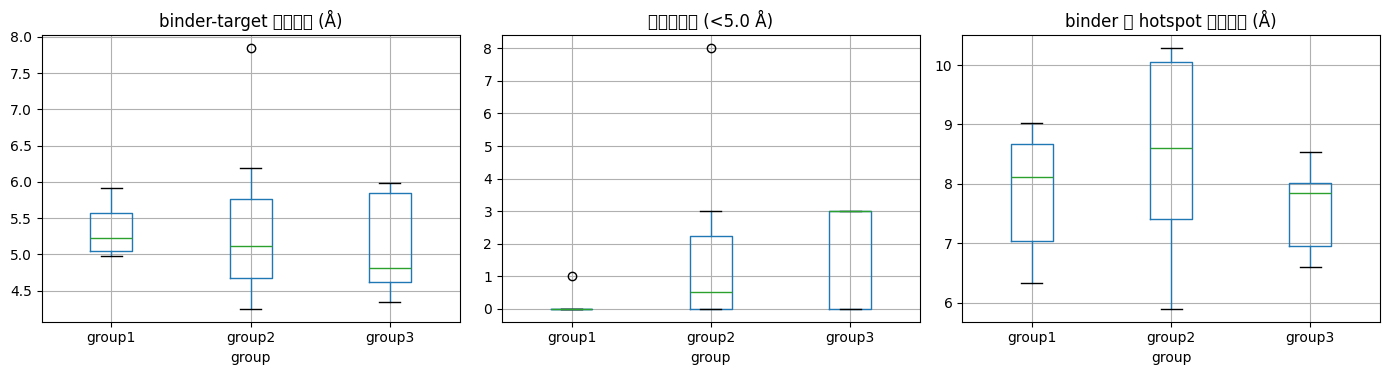

💾 已保存: /content/drive/MyDrive/RFdiffusion/backbone_interface_summary.csv


In [2]:
#@title 📏 骨架界面分析 (逐骨架 hotspot 映射 + 距离) { display-mode: "form" }
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from Bio.PDB import PDBParser, PDBList
from Bio.Align import PairwiseAligner
from Bio.Data.IUPACData import protein_letters_3to1
from google.colab import drive

if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

#@markdown ### 📁 路径
base_dir = "/content/drive/MyDrive/RFdiffusion" #@param {type:"string"}
binder_chain = "A" #@param {type:"string"}
target_chain = "B" #@param {type:"string"}
contact_cutoff = 5.0 #@param {type:"number"}

#@markdown ### 🎯 各组 hotspot (1IVO 编号)
ref_pdb_id = "1ivo" #@param {type:"string"}
ref_chain = "A" #@param {type:"string"}
hotspots = {
    "group1": [364, 367],
    "group2": [431, 400, 376],
    "group3": [392, 397],
}

parser = PDBParser(QUIET=True)

def residue_list(chain):
    out = []
    for r in chain:
        if r.id[0] != " ":
            continue
        aa = protein_letters_3to1.get(r.get_resname().capitalize())
        if aa:
            out.append((r.id[1], aa, r))
    return out

# --- 参考结构 ---
ref_path = PDBList().retrieve_pdb_file(ref_pdb_id, pdir="/content", file_format="pdb")
ref = residue_list(parser.get_structure("ref", ref_path)[0][ref_chain])
ref_seq = "".join(a for _, a, _ in ref)
ref_aa = {n: a for n, a, _ in ref}

aligner = PairwiseAligner()
aligner.mode = "local"
aligner.match_score, aligner.mismatch_score = 2, -1
aligner.open_gap_score, aligner.extend_gap_score = -5, -0.5

def map_numbers(sub):
    """返回 {1IVO编号: (骨架编号, 氨基酸是否一致)}"""
    sub_seq = "".join(a for _, a, _ in sub)
    aln = aligner.align(ref_seq, sub_seq)[0]
    m = {}
    for (r0, r1), (s0, s1) in zip(*aln.aligned):
        for k in range(r1 - r0):
            rn, ra, _ = ref[r0 + k]
            sn, sa, _ = sub[s0 + k]
            m[rn] = (sn, ra == sa)
    return m

def heavy(chain_res):
    return [a for r in chain_res for a in r if a.element != "H"]

rows = []
for g, hs in hotspots.items():
    files = sorted(glob.glob(os.path.join(base_dir, g, "*.pdb")))
    print(f"\n{g}: {len(files)} 个骨架, hotspot(1IVO) = {hs}")
    for f in files:
        name = os.path.basename(f)
        try:
            model = parser.get_structure("s", f)[0]
            if binder_chain not in model or target_chain not in model:
                print(f"  ⚠️ {name}: 链 ID 不匹配"); continue
            tgt = residue_list(model[target_chain])
            mp = map_numbers(tgt)
            cov = (min(mp), max(mp)) if mp else (None, None)

            b_atoms = heavy(model[binder_chain])
            t_atoms = heavy(model[target_chain])
            bc = np.array([a.coord for a in b_atoms])
            tc = np.array([a.coord for a in t_atoms])
            D = cdist(bc, tc)
            hit = D < contact_cutoff
            b_int = {b_atoms[i].get_parent().id[1] for i in np.where(hit.any(1))[0]}
            t_int = {t_atoms[j].get_parent().id[1] for j in np.where(hit.any(0))[0]}

            row = {"group": g, "file": name,
                   "target_range": f"{tgt[0][0]}-{tgt[-1][0]}",
                   "ref_covered": f"{cov[0]}-{cov[1]}",
                   "min_dist": round(float(D.min()), 2),
                   "n_atom_contacts": int(hit.sum()),
                   "n_binder_int_res": len(b_int),
                   "n_target_int_res": len(t_int)}

            hs_d = []
            for h in hs:
                if h not in mp:
                    row[f"hs{h}"] = "outside"; hs_d.append(np.nan); continue
                sn, same = mp[h]
                idx = [j for j, a in enumerate(t_atoms) if a.get_parent().id[1] == sn]
                d = float(D[:, idx].min())
                hs_d.append(d)
                row[f"hs{h}"] = f"{round(d,2)} (→{sn}{'' if same else ' ⚠aa不符'})"
            row["hs_min_dist"] = round(float(np.nanmin(hs_d)), 2) if not np.all(np.isnan(hs_d)) else np.nan
            row["hs_touched"] = int(np.sum(np.array(hs_d) < contact_cutoff))
            row["hs_total"] = len(hs)
            rows.append(row)
        except Exception as e:
            print(f"  ❌ {name}: {e}")

df_bb = pd.DataFrame(rows)
out_csv = os.path.join(base_dir, "backbone_interface_summary.csv")
df_bb.to_csv(out_csv, index=False)

pd.set_option("display.width", 250, "display.max_columns", 30)
display(df_bb)

summary = df_bb.groupby("group").agg(
    n=("file", "count"),
    min_dist_median=("min_dist", "median"),
    contacts_median=("n_atom_contacts", "median"),
    contacts_max=("n_atom_contacts", "max"),
    frac_touching=("min_dist", lambda x: (x <= 4.0).mean()),
    hs_min_dist_median=("hs_min_dist", "median"),
)
display(summary)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
df_bb.boxplot(column="min_dist", by="group", ax=ax[0]); ax[0].set_title("binder-target 最近距离 (Å)")
df_bb.boxplot(column="n_atom_contacts", by="group", ax=ax[1]); ax[1].set_title(f"原子接触数 (<{contact_cutoff} Å)")
df_bb.boxplot(column="hs_min_dist", by="group", ax=ax[2]); ax[2].set_title("binder 到 hotspot 最近距离 (Å)")
plt.suptitle(""); plt.tight_layout(); plt.show()
print(f"💾 已保存: {out_csv}")